# Parameter Estimation

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import pandas as pd 
import pymc
from mpl_toolkits import mplot3d
import scipy 




g++ not available, if using conda: `conda install gxx`


# Model setup

In [2]:
# Input parameters
t = np.arange(0.3,60, step=0.3)
s = np.arange(0,3.0,step = 0.5)
num_config = 1
if (num_config==1):
    # default params
    M = 10
    D = 0.07
    L = 1.505
    tau = 30.1525
    model_params = [M,D,L,tau]
    print(model_params)

print(s)
print(t)

# Ouput parameters


[10, 0.07, 1.505, 30.1525]
[0.  0.5 1.  1.5 2.  2.5]
[ 0.3  0.6  0.9  1.2  1.5  1.8  2.1  2.4  2.7  3.   3.3  3.6  3.9  4.2
  4.5  4.8  5.1  5.4  5.7  6.   6.3  6.6  6.9  7.2  7.5  7.8  8.1  8.4
  8.7  9.   9.3  9.6  9.9 10.2 10.5 10.8 11.1 11.4 11.7 12.  12.3 12.6
 12.9 13.2 13.5 13.8 14.1 14.4 14.7 15.  15.3 15.6 15.9 16.2 16.5 16.8
 17.1 17.4 17.7 18.  18.3 18.6 18.9 19.2 19.5 19.8 20.1 20.4 20.7 21.
 21.3 21.6 21.9 22.2 22.5 22.8 23.1 23.4 23.7 24.  24.3 24.6 24.9 25.2
 25.5 25.8 26.1 26.4 26.7 27.  27.3 27.6 27.9 28.2 28.5 28.8 29.1 29.4
 29.7 30.  30.3 30.6 30.9 31.2 31.5 31.8 32.1 32.4 32.7 33.  33.3 33.6
 33.9 34.2 34.5 34.8 35.1 35.4 35.7 36.  36.3 36.6 36.9 37.2 37.5 37.8
 38.1 38.4 38.7 39.  39.3 39.6 39.9 40.2 40.5 40.8 41.1 41.4 41.7 42.
 42.3 42.6 42.9 43.2 43.5 43.8 44.1 44.4 44.7 45.  45.3 45.6 45.9 46.2
 46.5 46.8 47.1 47.4 47.7 48.  48.3 48.6 48.9 49.2 49.5 49.8 50.1 50.4
 50.7 51.  51.3 51.6 51.9 52.2 52.5 52.8 53.1 53.4 53.7 54.  54.3 54.6
 54.9 55.2 55.5 55.8 56.1 

In [3]:
class environ():
    """
    Environmental model
    Source: https://www.sfu.ca/~ssurjano/environ.html
    params: [M,D, L, t]
    """
    def __init__(self, params, s, t):
        self.M = params[0]
        self.D = params[1]
        self.L = params[2]
        self.tau = params[3]
        self.s = s
        self.t = t
        self.ds = len(s)
        self.dt = len(t)
        self.dY = self.ds*self.dt
        #output Y
        self.Y = np.zeros([self.ds,self.dt])


    
    def f(self,s,t) -> float:
        def C(s,t)-> float:
            a1 =self.M/np.sqrt(4*np.pi*self.D*t)
            a2 = np.exp(-(np.square(s))/(4*self.D*t)) 
            if (self.tau < t):
                a3 = self.M/np.sqrt(4*np.pi*self.D*(t-self.tau))
                a4 = np.exp(-(np.square((s-self.L)))/(4*self.D*(t-self.tau)))
            else:
                a3 = 0
                a4 = 0
            c = a1*a2 + a3*a4
            return c
        f_eval = np.sqrt(4*np.pi)*C(s,t)
        return f_eval
    
    def run(self)-> np.ndarray:
        for i in range(self.ds):
            for j in range(self.dt):
                self.Y[i,j] = self.f(s[i],t[j])
        y_vector = self.Y.flatten()
        return y_vector
         


         

In [4]:
model = environ(model_params, s ,t)
y_vector = model.run()
y_matrix = model.Y
T,S = np.meshgrid(t,s)

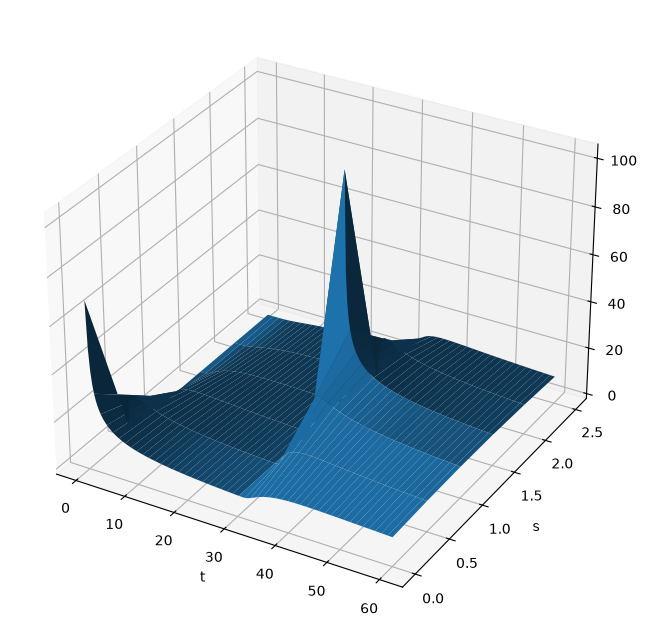

In [5]:
fig = plt.figure(figsize=(14,8))
ax = plt.axes(projection = '3d')
ax.plot_surface(T,S,y_matrix)
ax.set_xlabel('t')
ax.set_ylabel('s')
plt.show()

# Metropolis-Hastings Algorithm

In [6]:
np.random.seed(42)
#np.random.seed(123)

In [7]:
def MH(ground_truth:np.ndarray, measurements: np.ndarray, theta_0: np.ndarray, proposal_params:tuple, num_iterations:int):

    theta_samples = [np.zeros_like(theta_0)]*num_iterations
    theta_samples[0] = theta_0
    accepted_list = []

    def proposal(mu:float|np.ndarray,sigma:float, shape:tuple): 
        #assume normal distribution for proposal (instrumental) distribution
        # draw a candidate from this distribution
        #candidate = theta_0 + np.random.normal(loc = mu, scale = sigma , size =shape )
        candidate = np.random.normal(loc = mu, scale = sigma , size =shape )
       
        return candidate

    def target_distribution(theta:np.ndarray):
        new_model = environ(theta,s,t)
        predictions = new_model.run()
        loglikelihood = np.sum(scipy.stats.norm.logpdf(measurements, loc=predictions , scale = 1))
        logprior = scipy.stats.uniform.logpdf(theta, loc = [7, 0.02, 0.01, 30.01], scale = [6, 0.1, 2.99, 0.285])
        #logprior = scipy.stats.norm.logpdf(theta, loc = 10, scale = 1)
        return loglikelihood+logprior

    def acceptance_ratio(n,theta_prime,mu,sigma):
        candidate_q_prob = scipy.stats.norm.logpdf(theta_prime, loc = mu, scale = sigma)
        current_q_prob = scipy.stats.norm.logpdf(theta_samples[n-1], loc = theta_prime, scale = sigma)
        candidate_target_prob = target_distribution(theta_prime)
        current_target_prob = target_distribution(theta_samples[n-1])
        ratio = (candidate_target_prob - current_target_prob)+(current_q_prob-candidate_q_prob)
        #ratio = np.exp((candidate_target_prob - current_target_prob)+(current_q_prob-candidate_q_prob))
        return ratio


    for n in range(1,num_iterations):
        theta_prime = proposal(theta_samples[n-1],proposal_params[1], theta_0.shape)

        #calculated using logs
        alpha = acceptance_ratio(n,theta_prime, theta_samples[n-1], proposal_params[1])
        u = np.random.random_sample(1) # draw from uniform distibrution U[0,1)
        condition = np.log(u) <= np.minimum(0, alpha[0])
        #condition = u <= np.minimum(1, alpha)
        accepted_list.append(condition)
        if (condition):
            theta_samples[n] = theta_prime
        else:
            theta_samples[n] = theta_samples[n-1]

    return theta_samples, accepted_list

In [8]:
num_config = 4
lower_bounds = np.array([7, 0.02, 0.01, 30.01])
upper_bounds = np.array([13, 0.12, 3.0, 30.295])
theta_0 = np.random.uniform(lower_bounds, upper_bounds, size= lower_bounds.shape) #[7 to 13] for estimating M # assume uniform prior distribution
#M_0 = np.random.uniform(7,14,size= num_config) #[7 to 13] for estimating M # assume uniform prior distribution
#D_0 = np.random.uniform(0.02,0.12,size= num_config) #[0.02 to 0.12] for estimating D # assume uniform prior distribution
#L_0 = np.random.uniform(0.01,3.0,size= num_config) #[0.01 to 3.0] for estimating L # assume uniform prior distribution
#tau_0 = np.random.uniform(30.01,30.295,size= num_config) #[30.01 to 30.295] for estimating tau # assume uniform prior distribution
#theta_0 = np.array([M_0,D_0, L_0, tau_0])

proposal_params = (theta_0,0.1)
num_iterations = 20000
measurements = y_vector + np.random.normal(0,1, len(y_vector))

chain, acceptance_list = MH(ground_truth = y_vector, measurements = measurements, theta_0=theta_0, proposal_params=proposal_params, num_iterations=num_iterations)

C:\Users\glct1n26\AppData\Local\Temp\ipykernel_20000\3043290972.py:24: RuntimeWarning: invalid value encountered in sqrt
  a1 =self.M/np.sqrt(4*np.pi*self.D*t)
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_20000\3043290972.py:27: RuntimeWarning: invalid value encountered in sqrt
  a3 = self.M/np.sqrt(4*np.pi*self.D*(t-self.tau))
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_20000\3043290972.py:28: RuntimeWarning: overflow encountered in exp
  a4 = np.exp(-(np.square((s-self.L)))/(4*self.D*(t-self.tau)))
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_20000\3043290972.py:25: RuntimeWarning: overflow encountered in exp
  a2 = np.exp(-(np.square(s))/(4*self.D*t))


In [9]:
np.count_nonzero(acceptance_list)/ len(acceptance_list)

np.float64(0.0011500575028751438)

# Convergence Evaluation

In [10]:
print(chain[-1])

[10.22027199  0.07430465  1.5238563  30.1593769 ]


In [11]:
np.mean(chain, axis = 0)

array([10.11189331,  0.0721656 ,  1.52038572, 30.15564485])

In [12]:
y_vector.shape

(1200,)

In [13]:
np.mean(y_vector-measurements, axis = 0)

np.float64(-0.036575754390462026)

<function matplotlib.pyplot.show(close=None, block=None)>

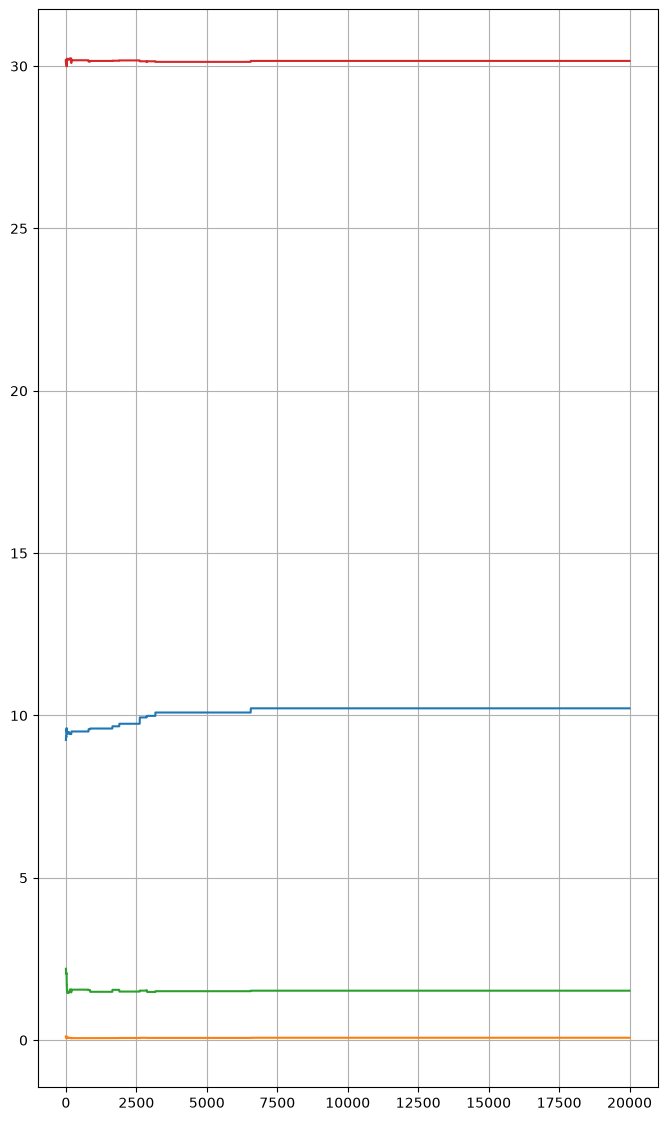

In [14]:
fig,ax = plt.subplots(ncols = 1, figsize=(8,14))
ax.plot(range(num_iterations), chain)
ax.grid()
plt.show

In [15]:
#test = np.array(chain)
#test[:,0]

<function matplotlib.pyplot.show(close=None, block=None)>

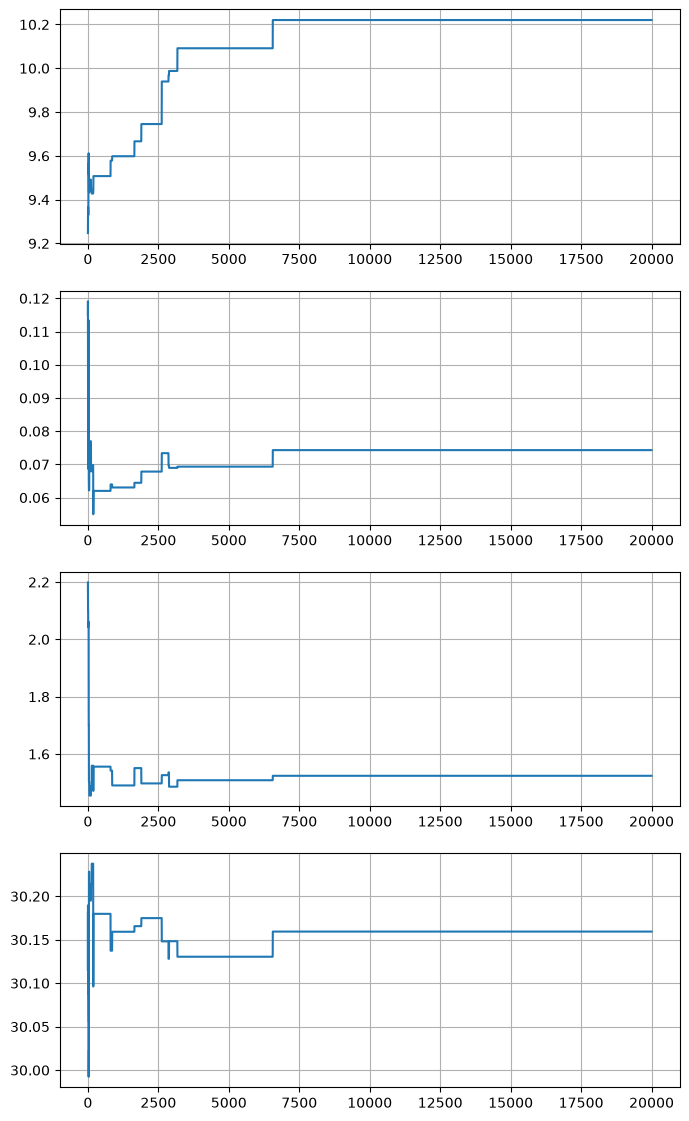

In [16]:
chain = np.array(chain)
fig,ax = plt.subplots(nrows = 4 , ncols = 1, figsize=(8,14))
for i in range(4):
    ax[i].plot(range(num_iterations), chain[:,i])
    ax[i].grid()
plt.show

# Convergence Analysis on samples after removing the warm-up/burn-in period

In [17]:
theta_0.shape[0]

4

In [18]:
num_iterations//2

10000

In [22]:
chain.shape

(20000, 4)

In [23]:
mc_chains = np.zeros((num_iterations//2, theta_0.shape[0]))
mc_chains[:,0] = chain[num_iterations//2:,0]
mc_chains[:,1] = chain[num_iterations//2:,1]
mc_chains[:,2] = chain[num_iterations//2:,2]
mc_chains[:,3] = chain[num_iterations//2:,3]


<function matplotlib.pyplot.show(close=None, block=None)>

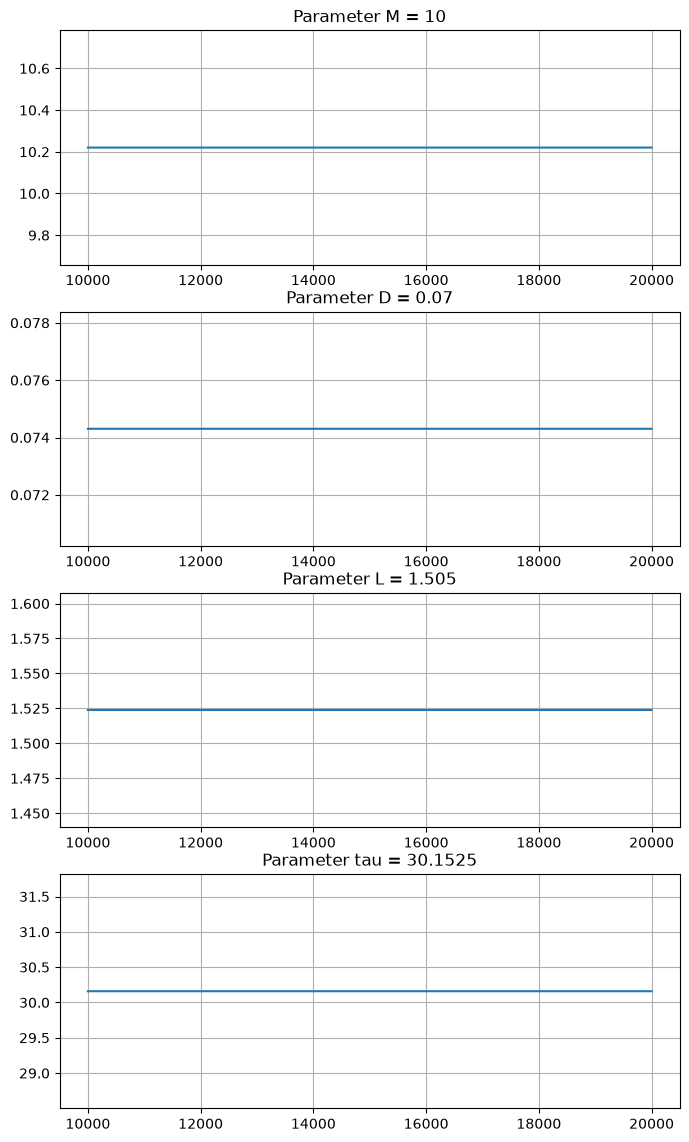

In [26]:
fig,ax = plt.subplots(nrows = 4 , ncols = 1, figsize=(8,14))
parameter_names = ['M','D','L','tau']

for i in range(4):
    ax[i].plot(range(num_iterations//2, num_iterations), mc_chains[:,i])
    ax[i].grid()
    ax[i].set_title(f'Parameter {parameter_names[i]} = {model_params[i]}')
plt.show

# Multiple Chains

In [ ]:
num_chains = 4
num_parameters = 4
num_iterations = 20000
measurements = y_vector + np.random.normal(0,1, len(y_vector))
mcmc_chains = np.zeros((num_chains, num_iterations, num_parameters))
acceptance_rates = np.zeros(num_chains)
for n in range(num_chains):
    lower_bounds = np.array([7, 0.02, 0.01, 30.01])
    upper_bounds = np.array([13, 0.12, 3.0, 30.295])
    theta_0 = np.random.uniform(lower_bounds, upper_bounds, size= lower_bounds.shape)
    proposal_params = (theta_0,0.1) 
    chain, acceptance_list = MH(ground_truth = y_vector, measurements = measurements, theta_0=theta_0, proposal_params=proposal_params, num_iterations=num_iterations)
    acceptance_rates[n] = np.count_nonzero(acceptance_list)/ len(acceptance_list)
    mcmc_chains[n] = chain

C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\3043290972.py:24: RuntimeWarning: invalid value encountered in sqrt
  a1 =self.M/np.sqrt(4*np.pi*self.D*t)
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\3043290972.py:27: RuntimeWarning: invalid value encountered in sqrt
  a3 = self.M/np.sqrt(4*np.pi*self.D*(t-self.tau))
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\3043290972.py:28: RuntimeWarning: overflow encountered in exp
  a4 = np.exp(-(np.square((s-self.L)))/(4*self.D*(t-self.tau)))
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\2973386325.py:28: RuntimeWarning: invalid value encountered in subtract
  ratio = (candidate_target_prob - current_target_prob)+(current_q_prob-candidate_q_prob)
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\3043290972.py:25: RuntimeWarning: overflow encountered in exp
  a2 = np.exp(-(np.square(s))/(4*self.D*t))


In [9]:
import pickle

In [11]:
pickle.dump(mcmc_chains, open('mcmc_chains.pickle', 'wb'))
pickle.dump(acceptance_rates, open('acceptance_rates.pickle', 'wb'))

In [12]:
acceptance_rates

array([0.00260013, 0.0020501 , 0.00055003, 0.00185009])

<function matplotlib.pyplot.show(close=None, block=None)>

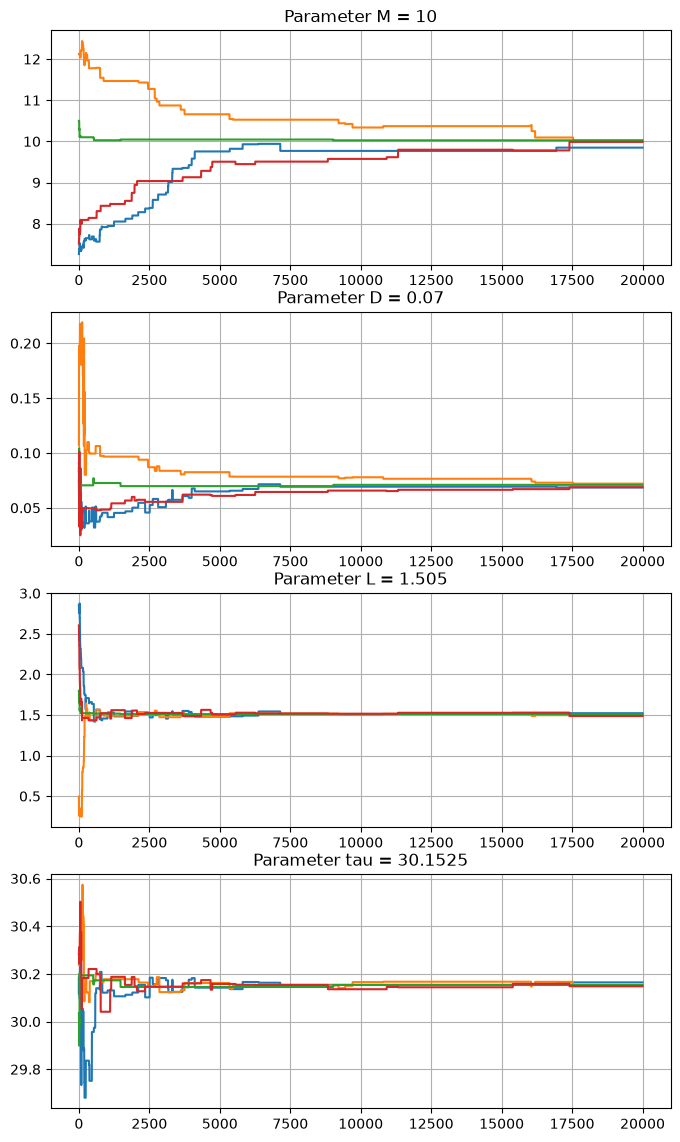

In [14]:
fig,ax = plt.subplots(nrows = 4 , ncols = 1, figsize=(8,14))
parameter_names = ['M','D','L','tau']

for i in range(4):
    for j in range(num_chains):
        ax[i].plot(range(num_iterations), mcmc_chains[j, :, i])
    ax[i].grid()
    ax[i].set_title(f'Parameter {parameter_names[i]} = {model_params[i]}')
plt.show

In [15]:
num_chains = 4
num_parameters = 4
num_iterations = 20000
measurements = y_vector + np.random.normal(0,1, len(y_vector))
mcmc_chains = np.zeros((num_chains, num_iterations, num_parameters))
acceptance_rates = np.zeros(num_chains)
for n in range(num_chains):
    lower_bounds = np.array([7, 0.02, 0.01, 30.01])
    upper_bounds = np.array([13, 0.12, 3.0, 30.295])
    theta_0 = np.random.uniform(lower_bounds, upper_bounds, size= lower_bounds.shape)
    proposal_params = (theta_0,1) 
    chain, acceptance_list = MH(ground_truth = y_vector, measurements = measurements, theta_0=theta_0, proposal_params=proposal_params, num_iterations=num_iterations)
    acceptance_rates[n] = np.count_nonzero(acceptance_list)/ len(acceptance_list)
    mcmc_chains[n] = chain

C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\3043290972.py:24: RuntimeWarning: invalid value encountered in sqrt
  a1 =self.M/np.sqrt(4*np.pi*self.D*t)
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\3043290972.py:27: RuntimeWarning: invalid value encountered in sqrt
  a3 = self.M/np.sqrt(4*np.pi*self.D*(t-self.tau))
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\3043290972.py:28: RuntimeWarning: overflow encountered in exp
  a4 = np.exp(-(np.square((s-self.L)))/(4*self.D*(t-self.tau)))
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\3043290972.py:25: RuntimeWarning: overflow encountered in exp
  a2 = np.exp(-(np.square(s))/(4*self.D*t))
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\2973386325.py:28: RuntimeWarning: invalid value encountered in subtract
  ratio = (candidate_target_prob - current_target_prob)+(current_q_prob-candidate_q_prob)


In [16]:
pickle.dump(mcmc_chains, open('mcmc_chains_proposal_1.0.pickle', 'wb'))
pickle.dump(acceptance_rates, open('acceptance_rates_proposal_1.0.pickle', 'wb'))

<function matplotlib.pyplot.show(close=None, block=None)>

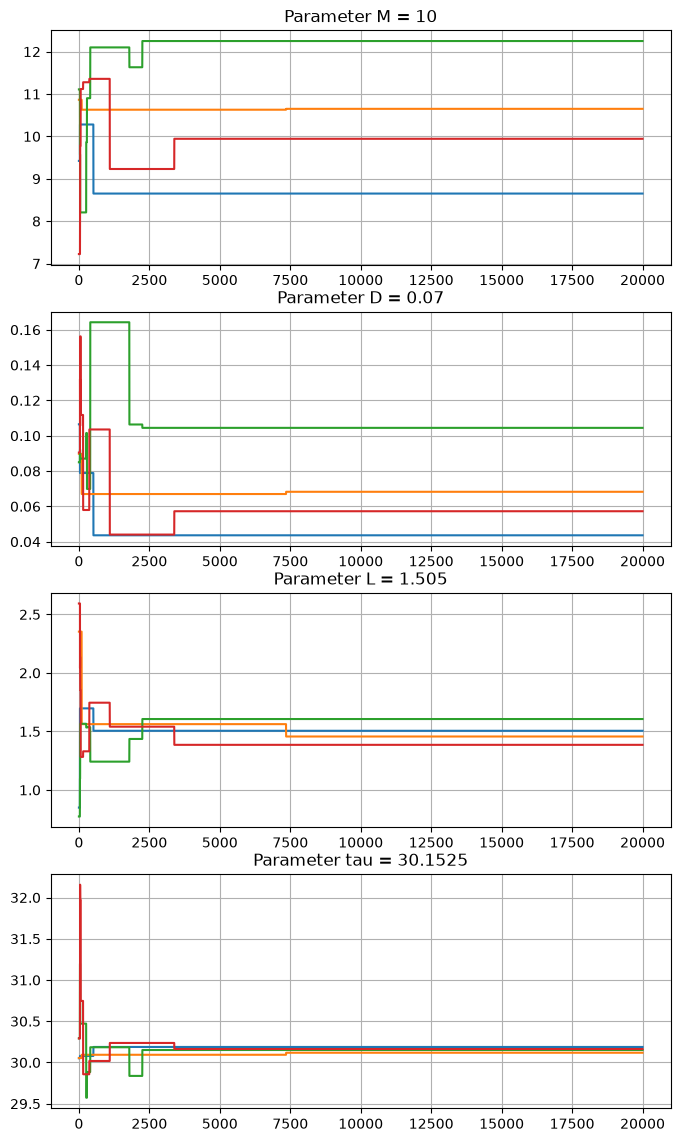

In [17]:
fig,ax = plt.subplots(nrows = 4 , ncols = 1, figsize=(8,14))
parameter_names = ['M','D','L','tau']

for i in range(4):
    for j in range(num_chains):
        ax[i].plot(range(num_iterations), mcmc_chains[j, :, i])
    ax[i].grid()
    ax[i].set_title(f'Parameter {parameter_names[i]} = {model_params[i]}')
plt.show

In [ ]:
num_chains = 4
num_parameters = 4
num_iterations = 20000
measurements = y_vector + np.random.normal(0,1, len(y_vector))
mcmc_chains = np.zeros((num_chains, num_iterations, num_parameters))
acceptance_rates = np.zeros(num_chains)
for n in range(num_chains):
    lower_bounds = np.array([7, 0.02, 0.01, 30.01])
    upper_bounds = np.array([13, 0.12, 3.0, 30.295])
    theta_0 = np.random.uniform(lower_bounds, upper_bounds, size= lower_bounds.shape)
    proposal_params = (theta_0,0.01) 
    chain, acceptance_list = MH(ground_truth = y_vector, measurements = measurements, theta_0=theta_0, proposal_params=proposal_params, num_iterations=num_iterations)
    acceptance_rates[n] = np.count_nonzero(acceptance_list)/ len(acceptance_list)
    mcmc_chains[n] = chain

C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\3043290972.py:24: RuntimeWarning: invalid value encountered in sqrt
  a1 =self.M/np.sqrt(4*np.pi*self.D*t)
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\3043290972.py:27: RuntimeWarning: invalid value encountered in sqrt
  a3 = self.M/np.sqrt(4*np.pi*self.D*(t-self.tau))
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\3043290972.py:28: RuntimeWarning: overflow encountered in exp
  a4 = np.exp(-(np.square((s-self.L)))/(4*self.D*(t-self.tau)))
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\3043290972.py:25: RuntimeWarning: overflow encountered in exp
  a2 = np.exp(-(np.square(s))/(4*self.D*t))
C:\Users\glct1n26\AppData\Local\Temp\ipykernel_8272\2973386325.py:28: RuntimeWarning: invalid value encountered in subtract
  ratio = (candidate_target_prob - current_target_prob)+(current_q_prob-candidate_q_prob)


In [ ]:
pickle.dump(mcmc_chains, open('mcmc_chains_proposal_0.01.pickle', 'wb'))
pickle.dump(acceptance_rates, open('acceptance_rates_proposal_0.01.pickle', 'wb'))